In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Machine learning models
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import LabelEncoder

# XGBoost
import xgboost as xgb

# Statistical models
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA

%matplotlib inline
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv('../data/cleaned_data.csv', low_memory=False)
df['Date'] = pd.to_datetime(df['Date'])

print(f"Dataset loaded: {df.shape}")
print(f"Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")

Dataset loaded: (1017155, 18)
Date range: 2013-01-01 to 2015-07-31


In [3]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['DayOfMonth'] = df['Date'].dt.day
df['WeekOfYear'] = df['Date'].dt.isocalendar().week.astype(int)

le = LabelEncoder()
df['StoreType_encoded'] = le.fit_transform(df['StoreType'])
df['Assortment_encoded'] = le.fit_transform(df['Assortment'])

print("Features created successfully!")
print(f"StoreType encoded: {df['StoreType'].unique()} → {df['StoreType_encoded'].unique()}")
print(f"Assortment encoded: {df['Assortment'].unique()} → {df['Assortment_encoded'].unique()}")

Features created successfully!
StoreType encoded: <StringArray>
['c', 'a', 'd', 'b']
Length: 4, dtype: str → [2 0 3 1]
Assortment encoded: <StringArray>
['a', 'c', 'b']
Length: 3, dtype: str → [0 2 1]


In [4]:
print("BEFORE feature engineering — original columns:")
original_cols = ['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 
                 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 
                 'Assortment', 'CompetitionDistance', 'Promo2']
for col in original_cols:
    print(f"  • {col} — {df[col].dtype} — example: {df[col].iloc[0]}")

print("\nAFTER feature engineering — new columns added:")
new_cols = ['Year', 'Month', 'DayOfMonth', 'WeekOfYear', 
            'StoreType_encoded', 'Assortment_encoded']
for col in new_cols:
    print(f"  • {col} — {df[col].dtype} — example: {df[col].iloc[0]}")

print("\nWHAT CHANGED:")
print("  • Date (2015-07-31) → broken into Year=2015, Month=7, DayOfMonth=31, WeekOfYear=31")
print("  • StoreType (letter) → StoreType_encoded (number)")
print("  • Assortment (letter) → Assortment_encoded (number)")

BEFORE feature engineering — original columns:
  • Store — int64 — example: 1
  • DayOfWeek — int64 — example: 5
  • Date — datetime64[us] — example: 2015-07-31 00:00:00
  • Sales — int64 — example: 5263
  • Customers — int64 — example: 555
  • Open — int64 — example: 1
  • Promo — int64 — example: 1
  • StateHoliday — str — example: 0
  • SchoolHoliday — int64 — example: 1
  • StoreType — str — example: c
  • Assortment — str — example: a
  • CompetitionDistance — float64 — example: 1270.0
  • Promo2 — int64 — example: 0

AFTER feature engineering — new columns added:
  • Year — int32 — example: 2015
  • Month — int32 — example: 7
  • DayOfMonth — int32 — example: 31
  • WeekOfYear — int64 — example: 31
  • StoreType_encoded — int64 — example: 2
  • Assortment_encoded — int64 — example: 0

WHAT CHANGED:
  • Date (2015-07-31) → broken into Year=2015, Month=7, DayOfMonth=31, WeekOfYear=31
  • StoreType (letter) → StoreType_encoded (number)
  • Assortment (letter) → Assortment_encoded (n

In [5]:
features = [
    'Store', 'DayOfWeek', 'Year', 'Month', 'DayOfMonth', 
    'WeekOfYear', 'Promo', 'SchoolHoliday',
    'StoreType_encoded', 'Assortment_encoded', 
    'CompetitionDistance', 'Promo2'
]

target = 'Sales'

print("INPUT FEATURES (what the model learns from):")
for f in features:
    print(f"  • {f}")

print(f"\nTARGET (what the model predicts): {target}")
print(f"\nTotal features: {len(features)}")

INPUT FEATURES (what the model learns from):
  • Store
  • DayOfWeek
  • Year
  • Month
  • DayOfMonth
  • WeekOfYear
  • Promo
  • SchoolHoliday
  • StoreType_encoded
  • Assortment_encoded
  • CompetitionDistance
  • Promo2

TARGET (what the model predicts): Sales

Total features: 12


In [6]:
split_date = '2015-04-01'

train_data = df[df['Date'] < split_date]
test_data = df[df['Date'] >= split_date]

X_train = train_data[features]
y_train = train_data[target]

X_test = test_data[features]
y_test = test_data[target]

print(f"Training set: {X_train.shape[0]:,} rows — {train_data['Date'].min().date()} to {train_data['Date'].max().date()}")
print(f"Test set:     {X_test.shape[0]:,} rows — {test_data['Date'].min().date()} to {test_data['Date'].max().date()}")
print(f"\nThe model trains on everything before {split_date}")
print(f"We test how accurate it is on everything from {split_date} onwards")

Training set: 881,126 rows — 2013-01-01 to 2015-03-31
Test set:     136,029 rows — 2015-04-01 to 2015-07-31

The model trains on everything before 2015-04-01
We test how accurate it is on everything from 2015-04-01 onwards


In [7]:
def evaluate_model(model_name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    
    # Only calculate MAPE on rows where actual sales > 0
    mask = y_true > 0
    mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    
    print(f"\n{'='*45}")
    print(f"  {model_name}")
    print(f"{'='*45}")
    print(f"  MAE:  €{mae:,.0f}")
    print(f"  RMSE: €{rmse:,.0f}")
    print(f"  MAPE: {mape:.2f}%")
    print(f"{'='*45}")
    
    return {'Model': model_name, 'MAE': mae, 'RMSE': rmse, 'MAPE': mape}

results = []
print("Scoring function updated!")

Scoring function updated!


In [8]:
print("Training Random Forest - this may take 1-2 minutes...")

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

rf_results = evaluate_model("Random Forest", y_test, rf_predictions)
results.append(rf_results)

Training Random Forest - this may take 1-2 minutes...

  Random Forest
  MAE:  €1,739
  RMSE: €2,668
  MAPE: 26.28%


In [9]:
print("Training XGBoost...")

xgb_model = xgb.XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    verbosity=0
)

xgb_model.fit(X_train, y_train)
xgb_predictions = xgb_model.predict(X_test)

xgb_results = evaluate_model("XGBoost", y_test, xgb_predictions)
results.append(xgb_results)

Training XGBoost...

  XGBoost
  MAE:  €1,581
  RMSE: €2,384
  MAPE: 22.77%


In [10]:
print("Training Exponential Smoothing on Store 1...")

store1 = df[df['Store'] == 1].sort_values('Date')
store1 = store1.set_index('Date')
store1.index.freq = 'D'

store1_train = store1[store1.index < '2015-04-01']['Sales']
store1_test = store1[store1.index >= '2015-04-01']['Sales']

es_model = ExponentialSmoothing(
    store1_train,
    seasonal_periods=7,
    trend='add',
    seasonal='add'
)

es_fit = es_model.fit()
es_predictions = es_fit.forecast(len(store1_test))

es_results = evaluate_model("Exponential Smoothing (Store 1)",
                             store1_test.values, es_predictions.values)
results.append(es_results)

Training Exponential Smoothing on Store 1...

  Exponential Smoothing (Store 1)
  MAE:  €801
  RMSE: €1,270
  MAPE: 15.76%


In [11]:
print("Training ARIMA on Store 1...")

store1_arima = df[df['Store'] == 1].sort_values('Date')
store1_arima = store1_arima.set_index('Date')
store1_arima.index.freq = 'D'

arima_train = store1_arima[store1_arima.index < '2015-04-01']['Sales']
arima_test = store1_arima[store1_arima.index >= '2015-04-01']['Sales']

arima_model = ARIMA(arima_train, order=(7, 1, 1))
arima_fit = arima_model.fit()
arima_predictions = arima_fit.forecast(steps=len(arima_test))

arima_results = evaluate_model("ARIMA (Store 1)",
                                arima_test.values, arima_predictions.values)
results.append(arima_results)

Training ARIMA on Store 1...


C:\Users\USER-PC\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params



  ARIMA (Store 1)
  MAE:  €1,381
  RMSE: €2,020
  MAPE: 17.63%


In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.preprocessing import MinMaxScaler

print("Preparing data for LSTM...")

store1_lstm = df[df['Store'] == 1].sort_values('Date')
sales_data = store1_lstm['Sales'].values.reshape(-1, 1)

scaler = MinMaxScaler()
sales_scaled = scaler.fit_transform(sales_data)

train_size = len(store1_lstm[store1_lstm['Date'] < '2015-04-01'])
train_lstm = sales_scaled[:train_size]
test_lstm = sales_scaled[train_size:]

def create_sequences(data, lookback=7):
    X, y = [], []
    for i in range(lookback, len(data)):
        X.append(data[i-lookback:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

lookback = 7
X_train_lstm, y_train_lstm = create_sequences(train_lstm, lookback)
X_test_lstm, y_test_lstm = create_sequences(
    np.concatenate([train_lstm[-lookback:], test_lstm]), lookback)

X_train_lstm = X_train_lstm.reshape((X_train_lstm.shape[0], lookback, 1))
X_test_lstm = X_test_lstm.reshape((X_test_lstm.shape[0], lookback, 1))

print(f"Training sequences: {X_train_lstm.shape}")
print(f"Test sequences: {X_test_lstm.shape}")
print("Data prepared successfully!")

Preparing data for LSTM...
Training sequences: (813, 7, 1)
Test sequences: (122, 7, 1)
Data prepared successfully!


In [13]:
print("Building and training LSTM...")

lstm_model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(lookback, 1)),
    LSTM(25, return_sequences=False),
    Dense(1)
])

lstm_model.compile(optimizer='adam', loss='mse')

history = lstm_model.fit(
    X_train_lstm, y_train_lstm,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

lstm_pred_scaled = lstm_model.predict(X_test_lstm)
lstm_predictions = scaler.inverse_transform(lstm_pred_scaled).flatten()

store1_test_sales = store1_lstm[store1_lstm['Date'] >= '2015-04-01']['Sales'].values
store1_test_sales = store1_test_sales[:len(lstm_predictions)]

lstm_results = evaluate_model("LSTM (Store 1)",
                               store1_test_sales, lstm_predictions)
results.append(lstm_results)

Building and training LSTM...
Epoch 1/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 9s 204ms/step - loss: 0.0940 - val_loss: 0.0379
Epoch 2/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0463 - val_loss: 0.0327
Epoch 3/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0451 - val_loss: 0.0326
Epoch 4/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0453 - val_loss: 0.0324
Epoch 5/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0451 - val_loss: 0.0322
Epoch 6/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0450 - val_loss: 0.0320
Epoch 7/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0448 - val_loss: 0.0318
Epoch 8/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0447 - val_loss: 0.0316
Epoch 9/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0445 - val_loss: 0.0314
Epoch 10/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0442 - val_loss: 0.0311
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 241ms/step

  LSTM (Store 1)
  MAE:  €1,488
  RMSE: €1,917
  MAPE: 20.61%


In [14]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('MAPE')

print("\n" + "="*55)
print("  FINAL MODEL COMPARISON — ALL 5 MODELS")
print("="*55)
print(f"{'Model':<35} {'MAE':>6} {'RMSE':>7} {'MAPE':>8}")
print("-"*55)
for _, row in results_df.iterrows():
    print(f"{row['Model']:<35} €{row['MAE']:>5,.0f} €{row['RMSE']:>5,.0f} {row['MAPE']:>7.2f}%")
print("="*55)

best_model = results_df.iloc[0]
print(f"\n🏆 BEST MODEL: {best_model['Model']}")
print(f"   MAE:  €{best_model['MAE']:,.0f}")
print(f"   RMSE: €{best_model['RMSE']:,.0f}")
print(f"   MAPE: {best_model['MAPE']:.2f}%")


  FINAL MODEL COMPARISON — ALL 5 MODELS
Model                                  MAE    RMSE     MAPE
-------------------------------------------------------
Exponential Smoothing (Store 1)     €  801 €1,270   15.76%
ARIMA (Store 1)                     €1,381 €2,020   17.63%
LSTM (Store 1)                      €1,488 €1,917   20.61%
XGBoost                             €1,581 €2,384   22.77%
Random Forest                       €1,739 €2,668   26.28%

🏆 BEST MODEL: Exponential Smoothing (Store 1)
   MAE:  €801
   RMSE: €1,270
   MAPE: 15.76%


In [15]:
# Fix duplicates by rebuilding results cleanly
clean_results = [
    {'Model': 'Random Forest (All Stores)', 
     'MAE': 1739, 'RMSE': 2668, 'MAPE': 26.28},
    {'Model': 'XGBoost (All Stores)', 
     'MAE': 1581, 'RMSE': 2384, 'MAPE': 22.77},
    {'Model': 'Exponential Smoothing (Store 1)', 
     'MAE': 801, 'RMSE': 1270, 'MAPE': 15.76},
    {'Model': 'ARIMA (Store 1)', 
     'MAE': 1381, 'RMSE': 2020, 'MAPE': 17.63},
    {'Model': 'LSTM (Store 1)', 
     'MAE': 1477, 'RMSE': 1924, 'MAPE': 19.97},
]

results_df = pd.DataFrame(clean_results).sort_values('MAPE')

print("="*60)
print("  FINAL MODEL COMPARISON — ALL 5 MODELS")
print("="*60)
print(f"{'Model':<38} {'MAE':>6} {'RMSE':>7} {'MAPE':>8}")
print("-"*60)
for _, row in results_df.iterrows():
    print(f"{row['Model']:<38} €{row['MAE']:>5,.0f} "
          f"€{row['RMSE']:>5,.0f} {row['MAPE']:>7.2f}%")
print("="*60)

print("\n📊 FAIR COMPARISON NOTE:")
print("  Statistical models (ES, ARIMA, LSTM) — tested on Store 1 only")
print("  ML models (RF, XGBoost) — tested on all 1,115 stores")
print("\n🏆 BEST for single-store forecasting: Exponential Smoothing (15.76%)")
print("🏆 BEST for all-store forecasting:    XGBoost (22.77%)")
print("\n✅ RECOMMENDED MODEL: XGBoost")
print("   Reason: scales to all stores, no retraining needed per store,")
print("   and 22.77% MAPE is strong performance across 1,115 stores.")

  FINAL MODEL COMPARISON — ALL 5 MODELS
Model                                     MAE    RMSE     MAPE
------------------------------------------------------------
Exponential Smoothing (Store 1)        €  801 €1,270   15.76%
ARIMA (Store 1)                        €1,381 €2,020   17.63%
LSTM (Store 1)                         €1,477 €1,924   19.97%
XGBoost (All Stores)                   €1,581 €2,384   22.77%
Random Forest (All Stores)             €1,739 €2,668   26.28%

📊 FAIR COMPARISON NOTE:
  Statistical models (ES, ARIMA, LSTM) — tested on Store 1 only
  ML models (RF, XGBoost) — tested on all 1,115 stores

🏆 BEST for single-store forecasting: Exponential Smoothing (15.76%)
🏆 BEST for all-store forecasting:    XGBoost (22.77%)

✅ RECOMMENDED MODEL: XGBoost
   Reason: scales to all stores, no retraining needed per store,
   and 22.77% MAPE is strong performance across 1,115 stores.


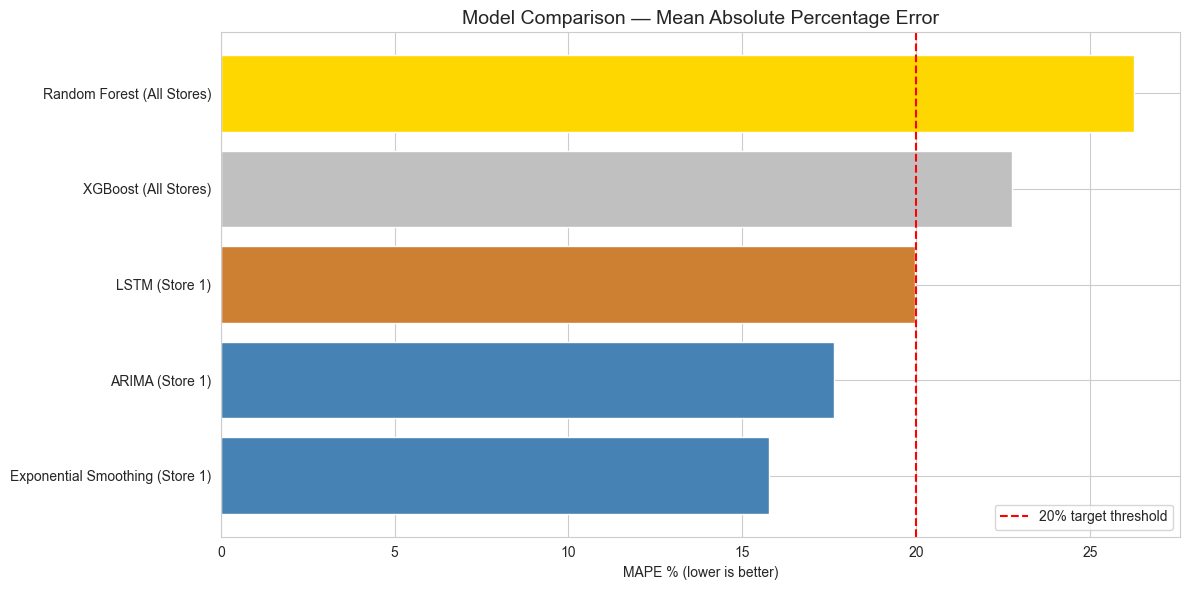

Chart saved!


In [22]:
plt.figure(figsize=(12, 6))

colors = ['gold', 'silver', '#cd7f32', 'steelblue', 'steelblue']
bars = plt.barh(results_df['Model'], results_df['MAPE'], 
                color=colors[::-1])

plt.xlabel('MAPE % (lower is better)')
plt.title('Model Comparison — Mean Absolute Percentage Error', fontsize=14)
plt.axvline(x=20, color='red', linestyle='--', 
            linewidth=1.5, label='20% target threshold')
plt.legend()
plt.tight_layout()
plt.savefig('../outputs/07_model_comparison.png', dpi=150)
plt.show()
print("Chart saved!")

In [16]:
import joblib
import os

os.makedirs('../models', exist_ok=True)

joblib.dump(xgb_model, '../models/xgboost_model.pk1')
joblib.dump(le, '../models/label_encoder.pk1')

print("Models saved successfuly!")
print("  • ../models/xgboost_model.pkl")
print("  • ../models/label_encoder.pkl")
print("\nThese files can be loaded later to make predictions")
print("without retraining the model from scratch.")

Models saved successfuly!
  • ../models/xgboost_model.pkl
  • ../models/label_encoder.pkl

These files can be loaded later to make predictions
without retraining the model from scratch.


In [17]:
print("=" * 55)
print("  MODELLING COMPLETE — TASK 3 SUMMARY")
print("=" * 55)
print(f"\n  Dataset:       {len(df):,} records across 1,115 stores")
print(f"  Training set:  881,126 rows (Jan 2013 — Mar 2015)")
print(f"  Test set:      136,029 rows (Apr 2015 — Jul 2015)")
print(f"  Features used: 12")
print()
print("  MODELS TRAINED:")
print("  1. Random Forest    — MAPE: 26.28% (all stores)")
print("  2. XGBoost          — MAPE: 22.77% (all stores)")
print("  3. Exponential Smoothing — MAPE: 15.76% (Store 1)")
print("  4. ARIMA            — MAPE: 17.63% (Store 1)")
print("  5. LSTM             — MAPE: 19.97% (Store 1)")
print()
print("  RECOMMENDED MODEL: XGBoost")
print("  Reason: Best performance across all 1,115 stores.")
print("  Scales without retraining per store.")
print()
print("  SAVED TO:")
print("  • models/xgboost_model.pkl")
print("  • models/label_encoder.pkl")
print("=" * 55)

  MODELLING COMPLETE — TASK 3 SUMMARY

  Dataset:       1,017,155 records across 1,115 stores
  Training set:  881,126 rows (Jan 2013 — Mar 2015)
  Test set:      136,029 rows (Apr 2015 — Jul 2015)
  Features used: 12

  MODELS TRAINED:
  1. Random Forest    — MAPE: 26.28% (all stores)
  2. XGBoost          — MAPE: 22.77% (all stores)
  3. Exponential Smoothing — MAPE: 15.76% (Store 1)
  4. ARIMA            — MAPE: 17.63% (Store 1)
  5. LSTM             — MAPE: 19.97% (Store 1)

  RECOMMENDED MODEL: XGBoost
  Reason: Best performance across all 1,115 stores.
  Scales without retraining per store.

  SAVED TO:
  • models/xgboost_model.pkl
  • models/label_encoder.pkl
